In [ ]:
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent

import pandas as pd

# pd.set_option('display.max_columns', None)
# pd.set_option('display.max_rows', None)

# ============================================================
# 0. 데이터 불러오기
# ============================================================

train = pd.read_parquet(PROJECT_ROOT / 'data' / '1_train_full_fe.parquet')
test = pd.read_parquet(PROJECT_ROOT / 'data' / '1_test_fe.parquet')

print(train.shape, test.shape)

(749657, 34) (186263, 33)


In [ ]:
# ============================================================
# 1. 컬럼군 정의
# ============================================================

# 종속변수군
target_col = 'target_maxrise_6h'

# 수위 컬럼군
wl_cols = [
    'wl_t',
    'wl_t_minus_1h',
    'wl_t_minus_3h',
    'wl_t_minus_6h',
    'wl_t_minus_12h',
    'wl_t_minus_24h',
]

# 수위차분(wl_diff) 컬럼군
wl_diff_cols = [
    'wl_t',
    'wl_diff_1h',
    'wl_diff_3h',
    'wl_diff_6h',
    'wl_diff_12h',
    'wl_diff_24h'
]

# 강수 컬럼군
rain_cols = [
    # IMERG강우
    'imerg_rain_1h',
    'imerg_rain_6h',
    'imerg_rain_24h',
    # 지상강우
    'sfc_rain_1h',
    'sfc_rain_6h',
    'sfc_rain_24h',
    # 레이더 반사도
    'radar_reflectivity_mean',
    'radar_reflectivity_p95',
    'radar_reflectivity_ge20_fraction'
]

# 강우강도 컬럼군
rain_int_cols = [
    'imerg_rain_1h',
    'imerg_int_1to6h',
    'imerg_int_6to24h',
    'sfc_rain_1h',
    'sfc_int_1to6h',
    'sfc_int_6to24h'
]

# 환경 컬럼군
env_cols = [
    'cat_area',       # km²
    'wsarea',         # km²
    'mean_elevation', # m
    'mean_slope',     # °
    'urban_ratio',    # %
    'forest_ratio',   # %
    'stream_order'
]

num_cols = train.select_dtypes(include='number').columns

assert len(num_cols) == 32, "'num_cols' 개수 이상"
assert (set(train.columns) - set(num_cols)) == {'station_id', 'timestamp'}, "'num_cols' 확인필요"

print(num_cols)  # target_col 포함됨

Index(['wl_t', 'wl_t_minus_1h', 'wl_t_minus_3h', 'wl_t_minus_6h',
       'wl_t_minus_12h', 'wl_t_minus_24h', 'imerg_rain_1h', 'imerg_rain_6h',
       'imerg_rain_24h', 'sfc_rain_1h', 'sfc_rain_6h', 'sfc_rain_24h',
       'radar_reflectivity_mean', 'radar_reflectivity_p95',
       'radar_reflectivity_ge20_fraction', 'cat_area', 'wsarea',
       'mean_elevation', 'mean_slope', 'urban_ratio', 'forest_ratio',
       'stream_order', 'target_maxrise_6h', 'wl_diff_1h', 'wl_diff_3h',
       'wl_diff_6h', 'wl_diff_12h', 'wl_diff_24h', 'imerg_int_1to6h',
       'imerg_int_6to24h', 'sfc_int_1to6h', 'sfc_int_6to24h'],
      dtype='object')


In [3]:
# ============================================================
# 2. station_id의 유역환경변수 유일성 확인하기
# ============================================================
# train, test셋의 station_id가 동일하면 env_cols는 서로 동일

print("===== Test에만 존재하는 컬럼 (없어야 정상) =====")
print(set(test.columns) - set(train.columns))

print("===== Train에만 존재하는 컬럼 (종속변수만 있어야 정상) =====")
print(set(train.columns) - set(test.columns))

assert (train.groupby('station_id')[env_cols].nunique().max() == 1).all(),  "관측소별 유역환경변수군의 데이터가 동일하지 않음"



===== Test에만 존재하는 컬럼 (없어야 정상) =====
set()
===== Train에만 존재하는 컬럼 (종속변수만 있어야 정상) =====
{'target_maxrise_6h'}


In [9]:
len(num_cols)

32



In [ ]:
# ======================================================================
# 3-1. train, test 데이터 박스플롯, 히스토그램, 분위수테이블 : 분포 비교용
# ======================================================================

import matplotlib.pyplot as plt

q = [0, 0.05, 0.5, 0.75, 0.9, 0.95, 0.99, 1.0]

fig, axes = plt.subplots(
    len(num_cols)-1,  # target_col은 따로 그릴 것이므로 행 하나가 남기때문에 -1
    3,
    figsize=(15, 4 * len(num_cols)),
    squeeze=False
)

for i, col in enumerate(
    [col for col in num_cols if col not in [target_col]]
):

    tr = train[col].dropna()
    te = test[col].dropna()

    # 1열: 박스플롯
    axes[i][0].boxplot(
        [tr, te],
        tick_labels=['train', 'Test']  # X축 이름
    )
    axes[i][0].set_title(f"{col}-Boxplot", fontsize=16)
    axes[i][0].tick_params(labelsize=12)

    # 2열: 히스토그램
    axes[i][1].hist(
        tr,
        range=(min(tr.min(), te.min()), max(tr.max(), te.max())),
        bins=30,
        alpha=0.5,
        density=True,
        label='Train'
    )
    axes[i][1].hist(
        te,
        range=(min(tr.min(), te.min()), max(tr.max(), te.max())),
        bins=30,
        alpha=0.5,
        density=True,
        label='Test'
    )
    axes[i][1].set_title(f"{col}-Histogram(Log-scale)", fontsize=16)
    axes[i][1].tick_params(labelsize=12)
    axes[i][1].legend()  # 범례
    axes[i][1].set_yscale('log')  # 히스토그램, 극단값의 낮은 값도 잘 보이게 로그스케일로

    # 3열: 분위수 비교표
    quant_df = pd.DataFrame({
        'Train': tr.quantile(q).round(2),
        'Test': te.quantile(q).round(2)
    })

    axes[i][2].axis('off')  # 그래프 축 제거

    table = axes[i][2].table(
        cellText=quant_df.values,
        rowLabels=[f'{v:.0%}' for v in q],
        colLabels=quant_df.columns,
        cellLoc='center',
        loc='center'
    )

    table.auto_set_font_size(False)
    table.set_fontsize(11)
    table.scale(1, 1.5)

    axes[i][2].set_title(f"{col}-Quantiles", fontsize=16)

plt.tight_layout()
plt.show()

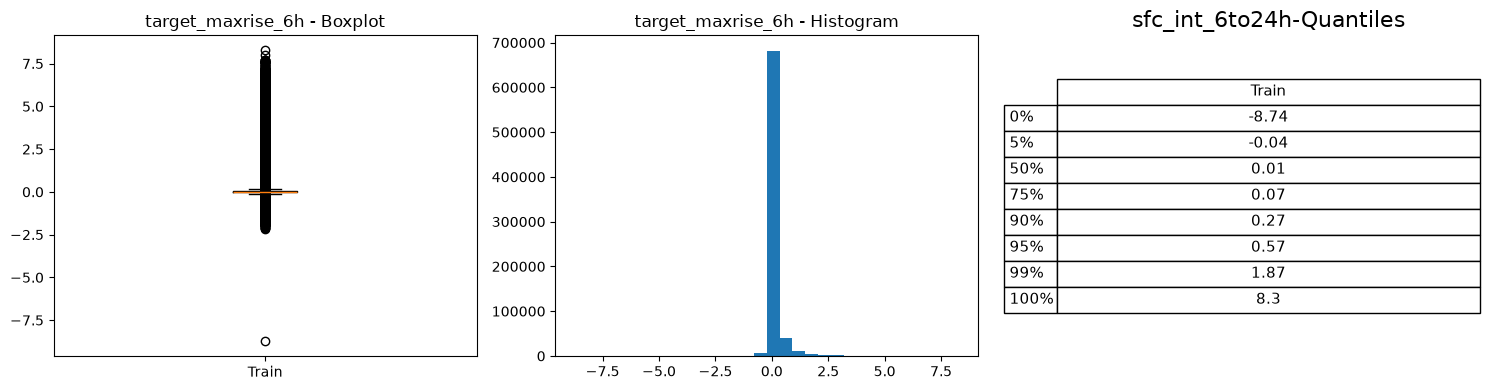

In [14]:
# ======================================================================
# 3-2. train 종속변수 데이터 박스플롯, 히스토그램, 분위수테이블 : 분포 비교용
# ======================================================================

tr = train[target_col].dropna()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].boxplot(tr, tick_labels=['Train'])
axes[0].set_title(f'{target_col} - Boxplot')

axes[1].hist(tr, bins=30)
axes[1].set_title(f'{target_col} - Histogram')

# 3열: 분위수테이블
q = [0, 0.05, 0.5, 0.75, 0.9, 0.95, 0.99, 1.0]

quant_df = pd.DataFrame({'Train': train[target_col].quantile(q).round(2)})

axes[2].axis('off')  # 그래프 축 제거

table = axes[2].table(
    cellText=quant_df.values,
    rowLabels=[f'{v:.0%}' for v in q],
    colLabels=quant_df.columns,
    cellLoc='center',
    loc='center'
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.5)

axes[2].set_title(f"{col}-Quantiles", fontsize=16)

plt.tight_layout()
plt.show()

In [ ]:
# ======================================================================
# 4. train 수치형변수와 종속변수간 산점도 그리기
# ======================================================================

import matplotlib.pyplot as plt

wl_diff_cols_only = [
    col for col in wl_diff_cols_EDA
    if col not in ['wl_t', 'target_maxrise_6h']
]

fig, axes = plt.subplots(
    len(wl_diff_cols_only),
    1,
    figsize=(
        6,
        4 * len(wl_diff_cols_only)
    )
)

if len(wl_diff_cols_only) == 1: # cols에 한개 열만 오면 axes = [ax1, ax2...]만 반환
    axes = [axes]  # axes = [[ax1, ax2]]가 돼야 행열(0행 0, 1열) 접근이 가능

for i, col in enumerate(wl_diff_cols_only):
    x = train_fe[col].dropna()  # 플롯을 여러개 그릴 예정, 플롯할 데이터를 하나의 변수로 묶어놓기(col임을 주의)

    axes[i].scatter(x, train_fe['target_maxrise_6h']) 
    axes[i].tick_params(labelsize = 10)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('target_maxrise_6h')

plt.tight_layout()  # 자동 간격조정(배치관리)
plt.show()
